<a href="https://colab.research.google.com/github/sukhadaghewari/tropicalcyclone-ri-bench/blob/main/notebooks/10_xgboost_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# XGBoost baseline on the same development and test cases

A trained machine-learning baseline for the LLM results. It follows the XGBoost setup of the CCAI tutorial on tropical cyclone RI prediction, with one change: it is scored on **exactly the same cases** as the LLMs, i.e. the same storms and the same observations (matched by `case_id`).

| Set | Seasons | Used for |
|---|---|---|
| Training | 1980–2015, all storms | fitting the model, choosing the number of trees and calibrating its probabilities |
| Development | 2016, the 40 storms (720 cases) in `model_inputs/ri_prediction/dev/` | nothing here; notebook 09 picks the threshold on it, as for the LLMs |
| Test | 2017–2025, the 100 storms (1,765 cases) in `model_inputs/ri_prediction/test/` | final scores, in notebook 09 |

**Features:** exactly the 16 features in the LLM prompts (`FEATURES` in `src/prompts.py`), so the comparison is like for like. Like the LLMs, the model sees no position, date or storm name.

The predictions are saved as `results/ri_prediction/<dev or test>/ml/xgboost_<case file name>.csv` (`case_id`, `ri_probability`). Notebook 09 reads them with the LLM answers and scores everything the same way.

## 1. Setup

Works out the repo folder and makes `src/` importable, as in the other notebooks. In Colab it first clones this repo.

In [1]:
# Setup: in Colab, clone the repo and move into it. Then put src/ on the import path.
import os, subprocess, sys
from pathlib import Path

REPO = "tropicalcyclone-ri-bench"
if "google.colab" in sys.modules:
    try:
        os.getcwd()
    except FileNotFoundError:              # the folder we were in was deleted (e.g. an old clone): start again
        os.chdir("/content")
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", f"https://github.com/sukhadaghewari/{REPO}.git"], check=True)
    os.chdir(REPO)
if "google.colab" in sys.modules:
    # A clone from an earlier run survives "Restart session": bring it up to date with GitHub.
    if subprocess.run(["git", "pull", "--ff-only"]).returncode != 0:
        print("WARNING: could not update the repo with git pull; using the files as they are.")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repo root, locally or in Colab
sys.path.insert(0, str(ROOT / "src"))

## 2. Settings

The XGBoost hyperparameters are the tutorial's, unchanged. `scale_pos_weight` is the training ratio of non-RI to RI cases, so the raw scores overstate the chance of RI; isotonic calibration (section 5) turns them back into probabilities.

In [2]:
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import GroupKFold
from xgboost import XGBClassifier

from prompts import FEATURES, TARGET, read_records

SEED = 42
TRAIN_CSV = ROOT / "data" / "ibtracs_era5_sat_1980_2015.csv.gz"    # written by 01_prepare_storm_data.ipynb
EVAL_CSV = ROOT / "data" / "ibtracs_era5_sat_2016_2025.csv.gz"
CASE_FILES = {
    "dev": ROOT / "model_inputs" / "ri_prediction" / "dev" / "dev_2016_20ri_20nori_text_only.jsonl.gz",
    "test": ROOT / "model_inputs" / "ri_prediction" / "test" / "test_2017-2025_50ri_50nori_text_only.jsonl.gz",
}
RESULTS_DIR = ROOT / "results" / "ri_prediction"
MODEL_NAME = "xgboost"
COLS = FEATURES        # exactly the 16 features the LLMs see, in the same order

XGB_PARAMS = dict(max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
                  reg_lambda=2.0, eval_metric="aucpr", n_jobs=-1, random_state=SEED)
MAX_TREES, EARLY_STOP, N_FOLDS = 600, 40, 5

## 3. Data

- **Training:** every labelled observation of the 1980–2015 seasons, built by notebook 01 with the same filters, features and RI label as the 2016–2025 file.
- **Development and test:** the rows of the 2016–2025 file for exactly the cases in the RI case files, in the same order. Each case's 16 feature values are checked against the last row of the history in its LLM prompt.

In [3]:
import json
import re

HISTORY_RE = re.compile(r"<storm_history>\n(.*?)\n</storm_history>", re.DOTALL)

read = lambda path: pd.read_csv(path, keep_default_na=False, na_values=[""], dtype={"sid": str})
train = read(TRAIN_CSV)
assert train["season"].between(1980, 2015).all()
data = read(EVAL_CSV)

sets = {}
for split, path in CASE_FILES.items():
    records = read_records(path)
    cases = pd.DataFrame(records).drop(columns="prompt")
    rows = cases[["case_id", "sid", "iso_time"]].merge(data, on=["sid", "iso_time"], how="left", validate="one_to_one")
    assert rows["usa_wind"].notna().all(), f"{split}: some cases have no row in {EVAL_CSV.name}"
    assert (rows[TARGET].astype(int).values == cases[TARGET].astype(int).values).all(), f"{split}: labels differ from the case file"
    assert not set(rows["sid"]) & set(train["sid"]), f"{split}: a storm is also in the training data"
    # The model's inputs must be what the LLM saw at the forecast time: the last row of the prompt's history.
    for record, (_, row) in zip(records, rows.iterrows()):
        last = json.loads(HISTORY_RE.search(record["prompt"]).group(1))[-1]
        for f in COLS:
            assert (last[f] is None and pd.isna(row[f])) or np.isclose(last[f], row[f], rtol=1e-5), f"{record['case_id']}: {f} differs from the prompt"
    sets[split] = rows

y_train = train[TARGET].astype(int)
print(f"training: {len(train):,} cases, {train['sid'].nunique():,} storms, seasons {train['season'].min()}-{train['season'].max()}, RI rate {y_train.mean():.3f}")
for split, rows in sets.items():
    print(f"{split}: {len(rows):,} cases, {rows['sid'].nunique()} storms, RI rate {rows[TARGET].astype(int).mean():.3f}")

training: 64,674 cases, 3,246 storms, seasons 1980-2015, RI rate 0.074
dev: 720 cases, 40 storms, RI rate 0.131
test: 1,765 cases, 100 storms, RI rate 0.108


## 4. Number of trees, by cross-validation on the training years

5-fold `GroupKFold` with the storm as the group, so one storm's observations never sit on both sides of a fold, as in the tutorial. Each fold stops early on its held-out storms; the mean stopping point becomes the number of trees. The development set is not used.

In [4]:
POS_WEIGHT = float((y_train == 0).sum() / (y_train == 1).sum())
folds = list(GroupKFold(n_splits=N_FOLDS).split(train, y_train, groups=train["sid"]))
print(f"scale_pos_weight = {POS_WEIGHT:.2f}")

X_train = train[COLS]
iters, scores = [], []
for tr, va in folds:
    m = XGBClassifier(n_estimators=MAX_TREES, early_stopping_rounds=EARLY_STOP, scale_pos_weight=POS_WEIGHT, **XGB_PARAMS)
    m.fit(X_train.iloc[tr], y_train.iloc[tr], eval_set=[(X_train.iloc[va], y_train.iloc[va])], verbose=False)
    iters.append(m.best_iteration + 1)
    scores.append(average_precision_score(y_train.iloc[va], m.predict_proba(X_train.iloc[va])[:, 1]))
N_TREES = int(np.mean(iters))
print(f"{len(COLS)} features | CV PR-AUC {np.mean(scores):.3f} ± {np.std(scores):.3f} | trees per fold {iters} -> {N_TREES}")

scale_pos_weight = 12.58


16 features | CV PR-AUC 0.406 ± 0.013 | trees per fold [191, 114, 259, 245, 186] -> 199


## 5. Calibration on out-of-fold training predictions

The tutorial calibrates on its validation years. Here the development set must stay untouched until notebook 09 picks the threshold, so the calibration map is fitted on **out-of-fold** predictions over the training years: each training case is scored by a model (with the chosen number of trees) that never saw its storm. Isotonic regression keeps the order of the scores, so ROC-AUC and PR-AUC are unaffected; only the probability values change.

In [5]:
oof = np.full(len(train), np.nan)
for tr, va in folds:
    m = XGBClassifier(n_estimators=N_TREES, scale_pos_weight=POS_WEIGHT, **XGB_PARAMS)
    m.fit(X_train.iloc[tr], y_train.iloc[tr], verbose=False)
    oof[va] = m.predict_proba(X_train.iloc[va])[:, 1]
assert not np.isnan(oof).any()                          # every training case scored exactly once
calibrator = IsotonicRegression(out_of_bounds="clip").fit(oof, y_train)
print(f"out-of-fold: mean raw score {oof.mean():.3f}, mean calibrated {calibrator.predict(oof).mean():.3f}, RI rate {y_train.mean():.3f}")

out-of-fold: mean raw score 0.295, mean calibrated 0.074, RI rate 0.074


## 6. Final model and predictions

The model is refit on all training years with that number of trees, then scores the development and test cases. The calibrated probabilities are saved for notebook 09.

In [6]:
model = XGBClassifier(n_estimators=N_TREES, scale_pos_weight=POS_WEIGHT, **XGB_PARAMS)
model.fit(X_train, y_train, verbose=False)

preds = {}
for split, rows in sets.items():
    p = calibrator.predict(model.predict_proba(rows[COLS])[:, 1])
    preds[split] = p
    out = RESULTS_DIR / split / "ml" / f"{MODEL_NAME}_{CASE_FILES[split].name.removesuffix('.jsonl.gz')}.csv"
    out.parent.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"case_id": rows["case_id"], "ri_probability": p.round(6)}).to_csv(out, index=False)
    print(f"saved {out.relative_to(ROOT)}")

saved results/ri_prediction/dev/ml/xgboost_dev_2016_20ri_20nori_text_only.csv
saved results/ri_prediction/test/ml/xgboost_test_2017-2025_50ri_50nori_text_only.csv


## 7. Quick look

Threshold-free scores only, for a first check. The full evaluation (thresholds chosen on the development set, confidence intervals, paired comparison with the best LLM) is in notebook 09. `BSS` uses the same reference as notebook 09: the development-set RI rate.

In [7]:
clim = sets["dev"][TARGET].astype(int).mean()
rows = []
for split, p in preds.items():
    y = sets[split][TARGET].astype(int).values
    rows.append({"set": split, "ROC-AUC": round(roc_auc_score(y, p), 3), "PR-AUC": round(average_precision_score(y, p), 3),
                 "BSS vs dev climatology": round(1 - np.mean((p - y) ** 2) / np.mean((clim - y) ** 2), 3),
                 "mean p / RI rate": f"{p.mean():.3f} / {y.mean():.3f}"})
pd.DataFrame(rows)

,set,ROC-AUC,PR-AUC,BSS vs dev climatology,mean p / RI rate
0,dev,0.891,0.560,0.265,0.088 / 0.131
1,test,0.837,0.439,0.209,0.087 / 0.108


## 8. Robustness: random seed

XGBoost samples rows and features at random (`subsample`, `colsample_bytree`), so the whole pipeline (number of trees, calibration, final model) is rerun with four more seeds. The spread should be far smaller than the bootstrap confidence intervals in notebook 09. The saved predictions above use `SEED` = 42 only.

In [8]:
def run_pipeline(seed):
    """Sections 4-6 with another random seed; returns the calibrated test probabilities and the number of trees."""
    params = {**XGB_PARAMS, "random_state": seed, "scale_pos_weight": POS_WEIGHT}
    n = int(np.mean([XGBClassifier(n_estimators=MAX_TREES, early_stopping_rounds=EARLY_STOP, **params)
                     .fit(X_train.iloc[tr], y_train.iloc[tr], eval_set=[(X_train.iloc[va], y_train.iloc[va])], verbose=False)
                     .best_iteration + 1 for tr, va in folds]))
    oof = np.full(len(train), np.nan)
    for tr, va in folds:
        oof[va] = XGBClassifier(n_estimators=n, **params).fit(X_train.iloc[tr], y_train.iloc[tr], verbose=False).predict_proba(X_train.iloc[va])[:, 1]
    cal = IsotonicRegression(out_of_bounds="clip").fit(oof, y_train)
    final = XGBClassifier(n_estimators=n, **params).fit(X_train, y_train, verbose=False)
    return cal.predict(final.predict_proba(sets["test"][COLS])[:, 1]), n


y_test = sets["test"][TARGET].astype(int).values
seed_rows = []
for seed in [SEED, 0, 1, 2, 3]:
    p, n = (preds["test"], N_TREES) if seed == SEED else run_pipeline(seed)
    seed_rows.append({"seed": seed, "trees": n, "ROC-AUC": round(roc_auc_score(y_test, p), 3),
                      "PR-AUC": round(average_precision_score(y_test, p), 3),
                      "BSS vs dev climatology": round(1 - np.mean((p - y_test) ** 2) / np.mean((clim - y_test) ** 2), 3)})
seed_table = pd.DataFrame(seed_rows)
(ROOT / "results" / "analysis" / "test").mkdir(parents=True, exist_ok=True)
seed_table.to_csv(ROOT / "results" / "analysis" / "test" / "ri_test_xgboost_seed_sensitivity.csv", index=False)
seed_table

,seed,trees,ROC-AUC,PR-AUC,BSS vs dev climatology
0,42,199,0.837,0.439,0.209
1,0,221,0.836,0.432,0.203
2,1,201,0.838,0.443,0.211
3,2,211,0.837,0.435,0.206
4,3,240,0.838,0.432,0.205


## 9. Feature importance

Which of the 16 features the final model (section 6) relies on. `gain` is the mean improvement in the training objective per split on that feature, `total gain` sums it over all splits, and `weight` is how often the feature is split on. The table is saved as `results/analysis/test/ri_test_xgboost_feature_importance.csv`. This is the model's own view, not a causal ranking: correlated features (e.g. wind speed and SSHS category) share credit arbitrarily.

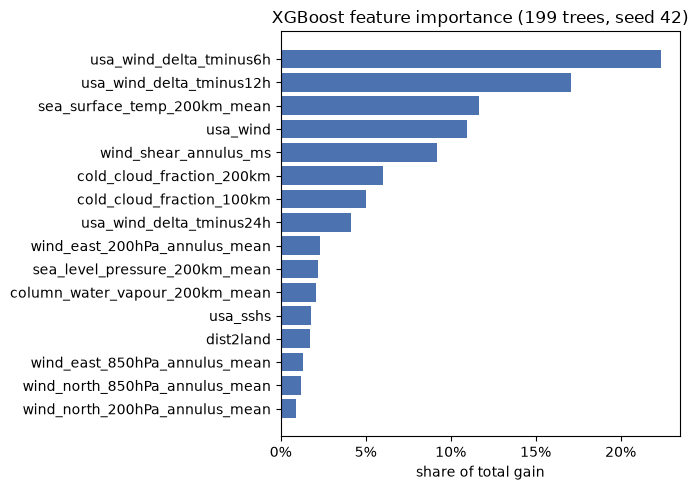

,feature,gain,total gain,weight,total gain share
0,usa_wind_delta_tminus6h,1193.022,140776.6,118.0,0.224
1,usa_wind_delta_tminus12h,986.433,107521.2,109.0,0.171
2,sea_surface_temp_200km_mean,255.040,73451.4,288.0,0.117
3,usa_wind,212.303,68998.4,325.0,0.110
4,wind_shear_annulus_ms,271.284,57783.5,213.0,0.092
5,cold_cloud_fraction_200km,194.127,38048.9,196.0,0.060
6,cold_cloud_fraction_100km,166.243,31586.1,190.0,0.050
7,usa_wind_delta_tminus24h,268.127,26008.3,97.0,0.041
8,wind_east_200hPa_annulus_mean,79.274,14507.2,183.0,0.023
9,sea_level_pressure_200km_mean,83.866,13921.8,166.0,0.022


In [9]:
import matplotlib.pyplot as plt

booster = model.get_booster()
imp = pd.DataFrame({"feature": COLS})
for kind, col in [("gain", "gain"), ("total_gain", "total gain"), ("weight", "weight")]:
    scores = booster.get_score(importance_type=kind)
    imp[col] = imp["feature"].map(scores).fillna(0.0)
imp["total gain share"] = imp["total gain"] / imp["total gain"].sum()
imp = imp.sort_values("total gain", ascending=False).reset_index(drop=True)
imp.to_csv(ROOT / "results" / "analysis" / "test" / "ri_test_xgboost_feature_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp["feature"][::-1], imp["total gain share"][::-1], color="#4C72B0")
ax.set_xlabel("share of total gain")
ax.set_title(f"XGBoost feature importance ({N_TREES} trees, seed {SEED})")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout()
plt.show()

imp.round({"gain": 3, "total gain": 1, "weight": 0, "total gain share": 3})

## Notes

- **Fair comparison:** the development and test cases are the LLM cases, row for row, and no training storm is in either set (checked in section 3). The development set is used only by notebook 09, to pick the threshold, exactly as for the LLMs.
- **Same features as the LLMs:** the 16 prompt features, checked value by value against each prompt (section 3). The tutorial's extra features (position, day of year, earlier wind values) are left out, because the LLMs never see them.
- **What the baseline sees:** one row per case, the forecast time only. Its view of the past comes from the wind changes over 6, 12 and 24 h. The LLMs see the whole history up to the forecast time.
- **Reproducibility:** seeds are fixed, but XGBoost trains in parallel, so the last digit can differ between computers (as the tutorial notes).